# Significant wave height compared with ERA5 and WHACS

Significant wave height ($H_s$) from the WAVEWATCH III component of an ACCESS-OM3 run, compared with
- ERA5 significant height of combined wind waves and swell (`swh`), and
- the WHACS WAVEWATCH III hindcast forced by ERA5 (Bureau of Meteorology / CSIRO).

WAVEWATCH III writes one instantaneous field per day at 00 UTC, so ERA5 and WHACS are sampled at the same 00 UTC times
(not daily means). All three datasets are regridded to a common 1° grid, and points where the model sea-ice
concentration (`ICE`) exceeds `ice_threshold` are excluded.

The climatology is the mean over the last `averaging_years` years that the model and ERA5 both cover. WHACS only
covers 1979–2023, so the WHACS comparison, the scatter plots and the exceedance curves use one year (`colocation_year`).

Related issue: [#78](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/78)

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the experiment of interest (must include WAVEWATCH III output)
esm_file = "/g/data/ol01/outputs/access-om3-100km/MCW_100km_era_iaf-test1-961264ad/experiment_datastore.json"

# Model variable (WAVEWATCH III daily snapshot output)
model_variable = "HS"
ice_variable = "ICE"

# Reference datasets (hourly)
era5_dir = "/g/data/rt52/era5/single-levels/reanalysis/swh"   # one sub-folder per year
era5_variable = "swh"
whacs_dir = "/g/data/ia39/WP3/release/ACS_hindcast/gridded/release/WP3/WHACS/BoM-CSIRO/hindcast/ERA5/ERA5/WHACS/WWIII-v6.07/global-R8/1hr/hs"
whacs_variable = "hs"

# Averaging window: the last `averaging_years` years covered by both the model and ERA5
averaging_years = 10
# Year used for the WHACS comparison, scatter plots and exceedance curves (None: last year covered by model and WHACS)
colocation_year = None
# Exclude points where the model sea-ice concentration is at or above this value
ice_threshold = 0.15
# Where to cache the 00 UTC reference fields and regridding weights (None: /scratch/$PROJECT/$USER/access-om3-paper-data/wave_obs)
cache_dir = None

# papermill settings. *No need to modify these if running interactively.*
papermill = False                 # `cwd` and `nbname` will be populated by papermill.
cwd = None
nbname = None

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-100km/MCW_100km_era_iaf-test1-961264ad/experiment_datastore.json"
papermill = True
cwd = "/g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/"
nbname = "Significant_wave_height_ERA5_comparison.ipynb"


In [3]:
if not papermill:
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs

In [4]:
ISSUE = "https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/78"
import glob
import os
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cft
import cmocean as cm
import intake
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xesmf as xe
from distributed import Client

xr.set_options(keep_attrs=True);

In [5]:
from model_agnostic import patch_dask_workers
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 190.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44369,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:43183,Total threads: 1
Dashboard: http://127.0.0.1:45037/status,Memory: 11.88 GiB
Nanny: tcp://127.0.0.1:36381,


## Model output

In [6]:
esm_path = Path(esm_file)
exptname = esm_path.parent.parent.name if esm_path.parent.name == "archive" else esm_path.parent.name

if cache_dir is None:
    cache_dir = f"/scratch/{os.environ['PROJECT']}/{os.environ['USER']}/access-om3-paper-data/wave_obs"
cache_dir = Path(cache_dir)
cache_dir.mkdir(parents=True, exist_ok=True)

datastore = intake.open_esm_datastore(esm_file, columns_with_iterables=["variable"])
wave_files = datastore.search(realm="wave", variable=[model_variable, ice_variable]).df
if len(wave_files) == 0:
    raise ValueError(f"No WAVEWATCH III files with {model_variable} and {ice_variable} in {esm_file}")

# One instantaneous field per file, stamped 00 UTC
wave_files = wave_files.assign(
    date=pd.to_datetime(wave_files["start_date"].str.replace(",", ""))
).sort_values("date")
model_first_year = wave_files["date"].min().year
model_last_year = (wave_files["date"].max() - pd.Timedelta(days=1)).year
print(f"{exptname}: {len(wave_files)} WAVEWATCH III files, {model_first_year}-{model_last_year}")

MCW_100km_era_iaf-test1-961264ad: 24472 WAVEWATCH III files, 1958-2024


In [7]:
def open_ww3(years):
    """Daily 00 UTC model fields (model_variable and ice_variable) for the given years."""
    sel = wave_files[wave_files["date"].dt.year.isin(list(years))]
    return xr.open_mfdataset(
        sel["path"].tolist(),
        combine="nested",
        concat_dim="time",
        parallel=True,
        data_vars="minimal",
        coords="minimal",
        compat="override",
        preprocess=lambda ds: ds[[model_variable, ice_variable]],
        chunks={},
    )


# Model grid (curvilinear WAVEWATCH III grid, longitude/latitude are 2D)
grid = xr.open_dataset(wave_files["path"].iloc[0])
model_grid = xr.Dataset(coords={"lon": grid["lon"], "lat": grid["lat"]})
model_grid_name = "x".join(str(n) for n in grid["lon"].shape)
units = grid[model_variable].attrs.get("units", "")
long_name = grid[model_variable].attrs.get("long_name", model_variable)
print(f"Model grid {model_grid_name}; {model_variable}: {long_name} [{units}]")

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e8125da810>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e77cf9c5f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e77cf8ccb0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e77cf8d940>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e77cf8d490>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e77cf8bec0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e74ede35f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


Model grid 324x360; HS: Significant wave height [m]


## Common 1° grid and reference datasets

In [8]:
target = xe.util.grid_global(1, 1)   # 180 x 360, cell centres -179.5..179.5, -89.5..89.5
area_weights = np.cos(np.deg2rad(target["lat"]))


def regridder_for(name, ds_in):
    weights = cache_dir / f"weights_{name}_to_1deg.nc"
    return xe.Regridder(
        ds_in, target, "bilinear", periodic=True, unmapped_to_nan=True,
        filename=str(weights), reuse_weights=weights.exists(),
    )


regrid_model = regridder_for(f"ww3_{model_grid_name}", model_grid)


def to_target(regridder, da):
    return regridder(da, skipna=True, na_thres=0.5)


def rectilinear(ds, lon="longitude", lat="latitude"):
    return ds.rename({lon: "lon", lat: "lat"}).sortby("lat")


def cached_reference_year(label, year, files, variable, coarsen=None):
    """00 UTC fields of `variable` for one year on the common 1° grid (cached)."""
    cache = cache_dir / f"{label}_{variable}_00utc_1deg_{year}.nc"
    if cache.exists():
        return xr.open_dataarray(cache)
    if len(files) == 0:
        raise FileNotFoundError(f"No {label} files for {year}")
    ds = xr.open_mfdataset(files, combine="by_coords", parallel=True, chunks={})
    da = ds[variable]
    da = da.sel(time=da.time.dt.hour == 0).astype("float32")
    da = rectilinear(da)
    if coarsen:
        da = da.coarsen(lon=coarsen, lat=coarsen, boundary="trim").mean()
    regridder = regridder_for(f"{label}_{da.sizes['lat']}x{da.sizes['lon']}", da.to_dataset(name=variable))
    out = to_target(regridder, da).compute()
    out.name = variable
    out.to_netcdf(cache)
    print(f"cached {cache}")
    return out


def era5_year(year):
    files = sorted(glob.glob(f"{era5_dir}/{year}/*.nc"))
    return cached_reference_year("era5", year, files, era5_variable)


def whacs_year(year):
    files = sorted(glob.glob(f"{whacs_dir}/{whacs_variable}_*_{year}??????00-*.nc"))
    # WHACS is 1/8 degree; average 8x8 blocks to about 1 degree before regridding
    return cached_reference_year("whacs", year, files, whacs_variable, coarsen=8)

In [9]:
era5_years = sorted(int(Path(p).name) for p in glob.glob(f"{era5_dir}/[0-9][0-9][0-9][0-9]")
                    if len(glob.glob(f"{p}/*.nc")) == 12)
whacs_years = sorted({int(Path(p).name.split("_")[-1][:4])
                      for p in glob.glob(f"{whacs_dir}/{whacs_variable}_*.nc")})

last_year = min(model_last_year, max(era5_years))
first_year = max(model_first_year, last_year - averaging_years + 1, min(era5_years))
window = range(first_year, last_year + 1)

if colocation_year is None:
    colocation_year = min(model_last_year, max(whacs_years))
if colocation_year not in whacs_years or not (model_first_year <= colocation_year <= model_last_year):
    raise ValueError(f"colocation_year {colocation_year} is not covered by both the model and WHACS")

print(f"Averaging window: {first_year}-{last_year}; colocation year: {colocation_year}")

Averaging window: 2015-2024; colocation year: 2023


## Colocated daily fields

In [10]:
def colocated(years, reference_year_fn):
    """Model and reference fields on the 1° grid at matching 00 UTC times; ice and missing data masked."""
    ref = xr.concat([reference_year_fn(y) for y in years], "time")
    model = open_ww3(years)
    model_t = to_target(regrid_model, model[model_variable]).astype("float32")
    ice_t = to_target(regrid_model, model[ice_variable]).astype("float32")
    model_t, ice_t, ref = xr.align(model_t, ice_t, ref, join="inner")
    valid = model_t.notnull() & ref.notnull() & (ice_t.fillna(0) < ice_threshold)
    return model_t.where(valid).persist(), ref.where(valid).persist()


model_win, era5_win = colocated(window, era5_year)
print("window samples:", model_win.sizes["time"])

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x154a0b334890>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1514ba7834a0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15461ec5f3b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1461745cb620>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14df5525bce0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1548223c6c00>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


... (89 outputs left out)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x148882050c20>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 266.47 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


window samples: 3653


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 2.02 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [11]:
def area_stats(diff):
    """Area-weighted mean and RMS of a 2D difference field."""
    w = area_weights.where(diff.notnull())
    mean = float((diff * w).sum() / w.sum())
    rmse = float(np.sqrt(((diff**2) * w).sum() / w.sum()))
    return mean, rmse


def time_mean(da, min_fraction=0.1):
    """Mean over valid samples; cells with fewer than min_fraction valid samples are left blank."""
    n = da.notnull().sum("time")
    return da.mean("time").where(n >= min_fraction * da.sizes["time"]).compute()


model_mean = time_mean(model_win)
era5_mean = time_mean(era5_win)
bias_era5 = model_mean - era5_mean
pct_era5 = 100 * bias_era5 / era5_mean
mean_bias_era5, rmse_era5 = area_stats(bias_era5)
print(f"{exptname} - ERA5 ({first_year}-{last_year}): mean bias {mean_bias_era5:.3f} {units}, RMSE {rmse_era5:.3f} {units}")

MCW_100km_era_iaf-test1-961264ad - ERA5 (2015-2024): mean bias -0.087 m, RMSE 0.174 m


## Plot functions

In [12]:
symbol = "$H_s$"
quantity = "significant wave height"
Quantity = "Significant wave height"
mean_levels = np.linspace(0, 6.0, 25)
bias_levels = np.linspace(-1.0, 1.0, 41)
pct_levels = np.linspace(-50.0, 50.0, 41)
scatter_max = 12.0


def map_panel(ax, da, title, levels, cmap, label):
    im = ax.pcolormesh(
        target["lon"], target["lat"], da, transform=ccrs.PlateCarree(), cmap=cmap,
        norm=mcolors.BoundaryNorm(levels, ncolors=plt.get_cmap(cmap).N, extend="both"),
    )
    ax.add_feature(cft.LAND, facecolor="lightgray", zorder=2)
    ax.coastlines(linewidth=0.5, zorder=3)
    ax.set_global()
    ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax, orientation="horizontal", shrink=0.8, pad=0.04, label=label)


def map_figure(panels):
    fig, axes = plt.subplots(
        2, 2, figsize=(13, 7.5), subplot_kw={"projection": ccrs.Robinson(central_longitude=-100)},
        constrained_layout=True,
    )
    for ax, args in zip(axes.flat, panels):
        map_panel(ax, *args)
    return fig

## Significant wave height climatology compared with ERA5

Saved /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison_01.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md


Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md successfully.


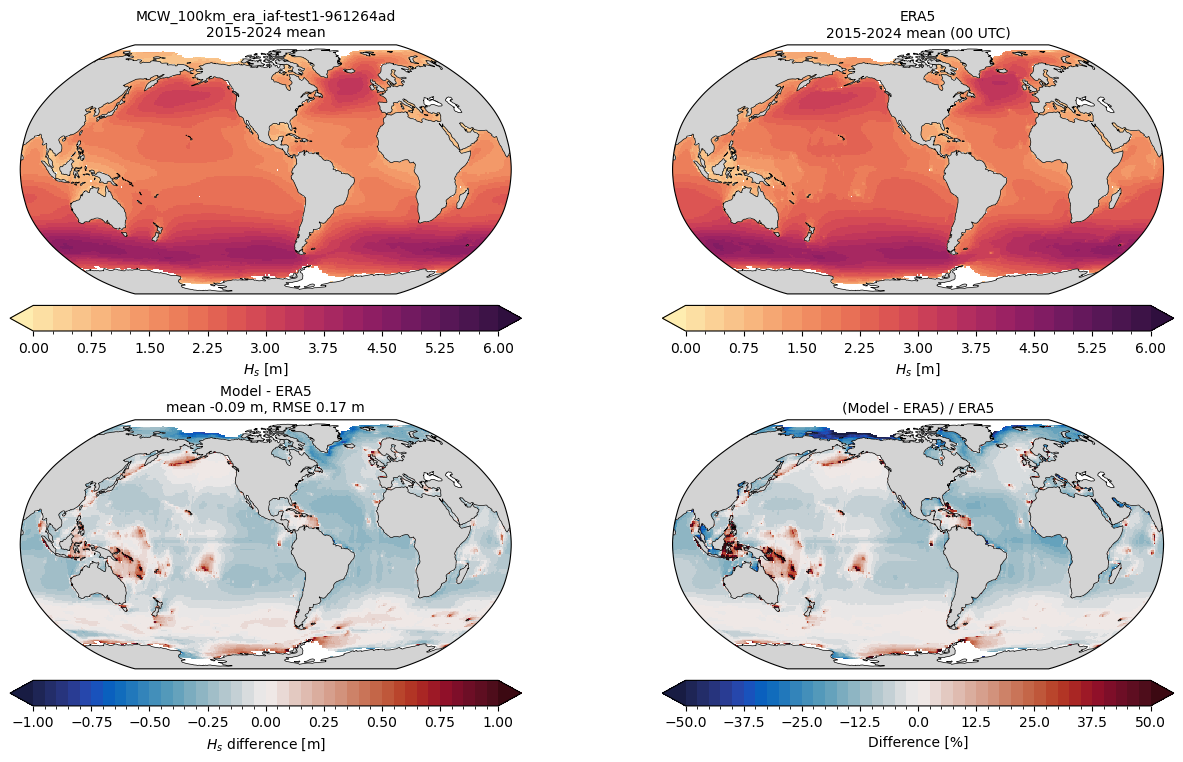

In [13]:
period = f"{first_year}-{last_year}"
fig = map_figure([
    (model_mean, f"{exptname}\n{period} mean", mean_levels, cm.cm.matter, f"{symbol} [{units}]"),
    (era5_mean, f"ERA5\n{period} mean (00 UTC)", mean_levels, cm.cm.matter, f"{symbol} [{units}]"),
    (bias_era5, f"Model - ERA5\nmean {mean_bias_era5:.2f} {units}, RMSE {rmse_era5:.2f} {units}",
     bias_levels, cm.cm.balance, f"{symbol} difference [{units}]"),
    (pct_era5, "(Model - ERA5) / ERA5", pct_levels, cm.cm.balance, "Difference [%]"),
])
mkmd.savefig(
    fig,
    f"{Quantity} compared with ERA5",
    f"{exptname} {quantity} averaged over {period} (00 UTC daily snapshots), ERA5 sampled at the same times, "
    f"and their difference. Points where the model sea-ice concentration is at least {ice_threshold} are excluded. "
    f"[GitHub issue: ERA5 wave parameter comparison]({ISSUE})",
)

Saved /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison_02.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md successfully.


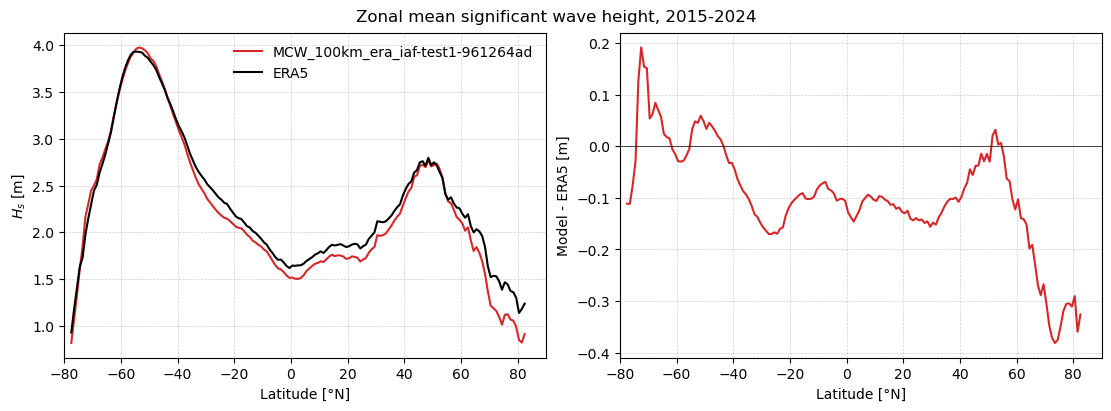

In [14]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
lat1d = target["lat"].isel(x=0)
ax0.plot(lat1d, model_mean.mean("x"), label=exptname, color="tab:red")
ax0.plot(lat1d, era5_mean.mean("x"), label="ERA5", color="k")
ax0.set_ylabel(f"{symbol} [{units}]")
ax0.legend(frameon=False)
ax1.plot(lat1d, bias_era5.mean("x"), color="tab:red")
ax1.axhline(0, color="k", linewidth=0.5)
ax1.set_ylabel(f"Model - ERA5 [{units}]")
for ax in (ax0, ax1):
    ax.set_xlabel("Latitude [°N]")
    ax.set_xlim(-80, 90)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)
fig.suptitle(f"Zonal mean {quantity}, {period}")
mkmd.savefig(
    fig,
    f"Zonal mean {quantity}",
    f"Zonal mean {quantity} in {exptname} and ERA5 over {period}, and their difference. "
    f"[GitHub issue: ERA5 wave parameter comparison]({ISSUE})",
)

## Comparison with WHACS and ERA5 in one year

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 53.66 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 234.15 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 53.66 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 234.15 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Saved /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison_03.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md successfully.


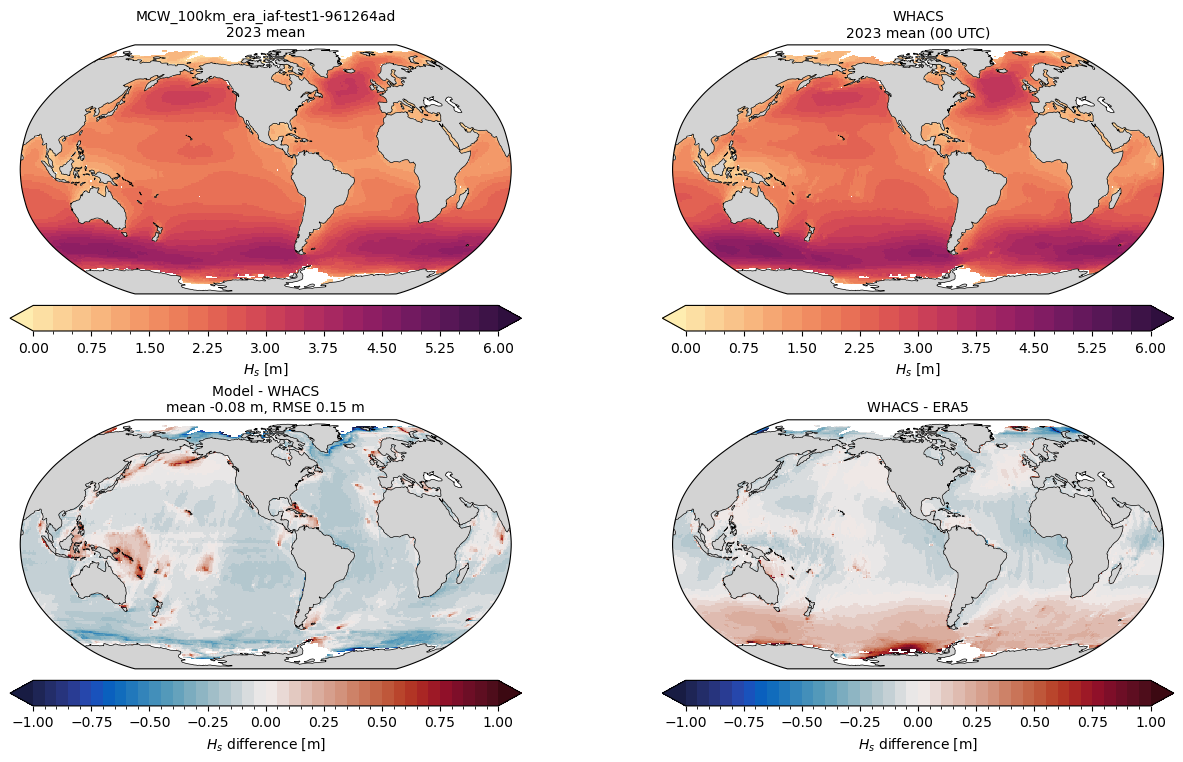

In [15]:
model_col, era5_col = colocated([colocation_year], era5_year)
model_colw, whacs_col = colocated([colocation_year], whacs_year)
# Common sample: valid in the model, ERA5 and WHACS at the same time and place
model_col, era5_col, model_colw, whacs_col = xr.align(model_col, era5_col, model_colw, whacs_col, join="inner")
common = model_col.notnull() & era5_col.notnull() & whacs_col.notnull()
model_col, era5_col, whacs_col = (da.where(common).compute() for da in (model_col, era5_col, whacs_col))

bias_whacs = time_mean(model_col) - time_mean(whacs_col)
obs_diff = time_mean(whacs_col) - time_mean(era5_col)
mean_bias_whacs, rmse_whacs = area_stats(bias_whacs)

fig = map_figure([
    (time_mean(model_col), f"{exptname}\n{colocation_year} mean", mean_levels, cm.cm.matter, f"{symbol} [{units}]"),
    (time_mean(whacs_col), f"WHACS\n{colocation_year} mean (00 UTC)", mean_levels, cm.cm.matter, f"{symbol} [{units}]"),
    (bias_whacs, f"Model - WHACS\nmean {mean_bias_whacs:.2f} {units}, RMSE {rmse_whacs:.2f} {units}",
     bias_levels, cm.cm.balance, f"{symbol} difference [{units}]"),
    (obs_diff, "WHACS - ERA5", bias_levels, cm.cm.balance, f"{symbol} difference [{units}]"),
])
mkmd.savefig(
    fig,
    f"{Quantity} compared with WHACS",
    f"{exptname} and WHACS {quantity} averaged over {colocation_year} at matching 00 UTC times, their difference, "
    f"and the WHACS - ERA5 difference for reference. "
    f"[GitHub issue: ERA5 wave parameter comparison]({ISSUE})",
)

Saved /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison_04.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md successfully.


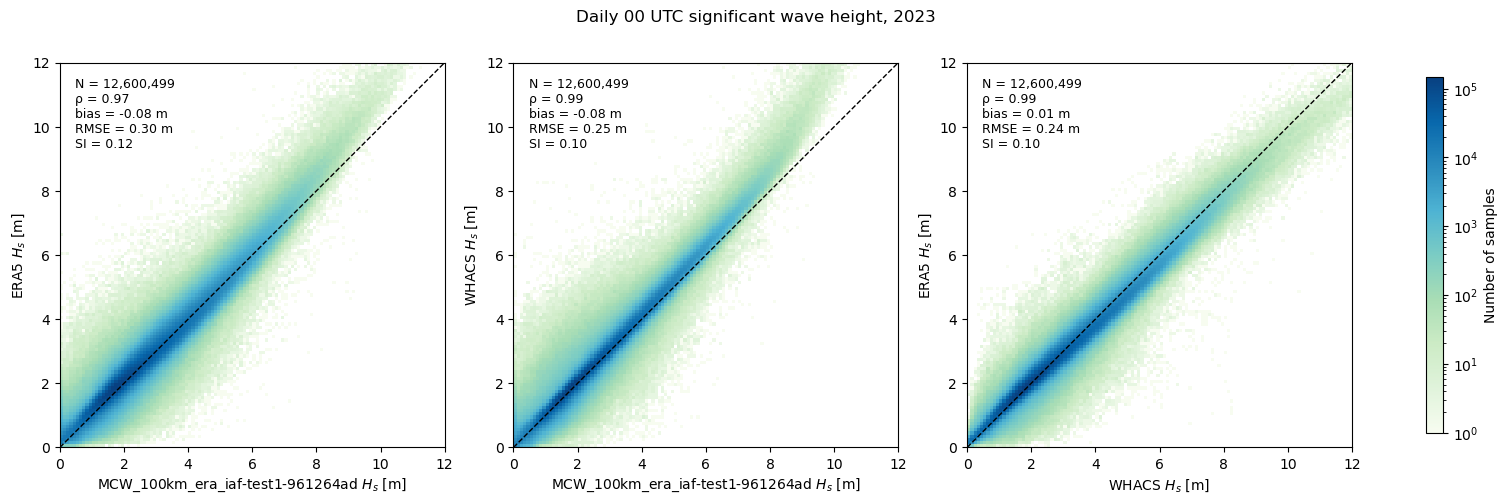

In [16]:
def flat(*das):
    vals = [da.values.ravel() for da in das]
    ok = np.logical_and.reduce([np.isfinite(v) for v in vals])
    return [v[ok] for v in vals]


def scatter_panel(ax, x, y, xlabel, ylabel):
    h = ax.hist2d(x, y, bins=120, range=[[0, scatter_max], [0, scatter_max]], cmap="GnBu", norm=mcolors.LogNorm())
    ax.plot([0, scatter_max], [0, scatter_max], "k--", linewidth=1)
    rho = np.corrcoef(x, y)[0, 1]
    bias = np.mean(x - y)
    rmse = np.sqrt(np.mean((x - y) ** 2))
    ax.text(0.04, 0.96, f"N = {x.size:,}\nρ = {rho:.2f}\nbias = {bias:.2f} {units}\nRMSE = {rmse:.2f} {units}\nSI = {rmse / np.mean(y):.2f}",
            transform=ax.transAxes, va="top", fontsize=9)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_aspect("equal")
    return h[3]


m, e, w = flat(model_col, era5_col, whacs_col)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
scatter_panel(axes[0], m, e, f"{exptname} {symbol} [{units}]", f"ERA5 {symbol} [{units}]")
scatter_panel(axes[1], m, w, f"{exptname} {symbol} [{units}]", f"WHACS {symbol} [{units}]")
im = scatter_panel(axes[2], w, e, f"WHACS {symbol} [{units}]", f"ERA5 {symbol} [{units}]")
fig.colorbar(im, ax=axes, shrink=0.8, label="Number of samples")
fig.suptitle(f"Daily 00 UTC {quantity}, {colocation_year}")
mkmd.savefig(
    fig,
    f"{Quantity} scatter against ERA5 and WHACS",
    f"Daily 00 UTC {quantity} on the common 1° grid in {colocation_year}, for points that are ice-free and valid in "
    f"all three datasets. Statistics are the first dataset minus the second; SI is RMSE divided by the second mean. "
    f"[GitHub issue: ERA5 wave parameter comparison]({ISSUE})",
)

Saved /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison_05.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mcw100era5/notebooks/mkfigs_output_MCW_100km_era_iaf-test1-961264ad/mkmd/Significant_wave_height_ERA5_comparison.md successfully.


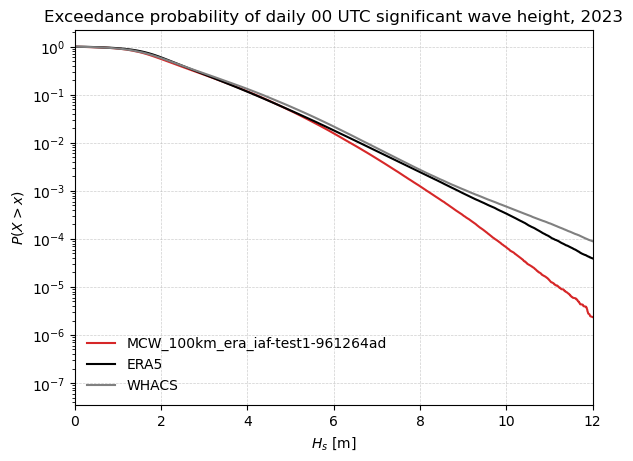

In [17]:
def exceedance(v):
    x = np.sort(v)
    return x, 1 - np.arange(1, x.size + 1) / x.size


fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
for v, label, colour in [(m, exptname, "tab:red"), (e, "ERA5", "k"), (w, "WHACS", "gray")]:
    ax.plot(*exceedance(v), label=label, color=colour)
ax.set_yscale("log")
ax.set_xlim(0, scatter_max)
ax.set_xlabel(f"{symbol} [{units}]")
ax.set_ylabel("$P(X > x)$")
ax.legend(frameon=False, loc="lower left")
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)
ax.set_title(f"Exceedance probability of daily 00 UTC {quantity}, {colocation_year}")
mkmd.savefig(
    fig,
    f"{Quantity} exceedance probability",
    f"Probability that daily 00 UTC {quantity} exceeds a given value in {colocation_year}, using the same samples "
    f"as the scatter plots. [GitHub issue: ERA5 wave parameter comparison]({ISSUE})",
)

In [18]:
client.close()

2026-11-04 22:01:51,332 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


2026-11-04 22:01:51,338 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing
